In [ ]:
# ============================================================
# Cell 1: Setup, load raw files, clean
# ============================================================
from google.colab import drive
drive.mount("/content/drive")
%cd /content/drive/MyDrive/burnwise

import json
import numpy as np
import pandas as pd

# ---------- Config ----------
MODIS_FILE = "modis.csv.csv"
VIIRS_FILE = "viirs.csv.csv"
START_DATE = "2003-01-01"
END_DATE   = "2026-07-31"
MIN_MODIS_CONF = 30          # MODIS confidence is numeric (0-100)
VIIRS_KEEP_CONF = ["n", "h"] # VIIRS confidence is a letter (l / n / h): drop "l"
GRID_SIZE = 0.25
SWITCH_YEAR = 2013           # from this year on, real VIIRS counts are used
RATIO_YEARS = (2013, 2022)   # years used to estimate the VIIRS/MODIS ratio
LAST_FULL_YEAR = 2025        # last complete year (used for the monthly median)
PARTIAL_YEARS = [2026]       # data ends 2026-07-31

# ---------- Load ----------
modis = pd.read_csv("fire_archive_M-C61_844758_modis_important.csv")
viirs = pd.read_csv("fire_archive_SV-C2_844759_viirs_important.csv")

# ---------- Clean ----------
def clean(df, name, conf_rule):
    """Remove duplicates, restrict dates, keep vegetation fires (type 0), filter confidence."""
    df = df.copy()
    df["acq_date"] = pd.to_datetime(df["acq_date"])
    log = [("start", len(df))]

    df = df.drop_duplicates(subset=["latitude", "longitude", "acq_date", "acq_time"])
    log.append(("remove duplicates", len(df)))

    df = df[(df["acq_date"] >= START_DATE) & (df["acq_date"] <= END_DATE)]
    log.append((f"dates {START_DATE}..{END_DATE}", len(df)))

    df = df[df["type"] == 0]
    log.append(("type == 0 (vegetation)", len(df)))

    df = df[conf_rule(df["confidence"])]
    log.append(("confidence filter", len(df)))

    print(f"--- {name} ---")
    prev = None
    for step, n in log:
        removed = "" if prev is None else f"  (removed {prev - n})"
        print(f"{step:<32}{n:>8}{removed}")
        prev = n
    print()
    return df.reset_index(drop=True)

modis_c = clean(modis, "MODIS", lambda c: c >= MIN_MODIS_CONF)
viirs_c = clean(viirs, "VIIRS", lambda c: c.astype(str).str.lower().isin(VIIRS_KEEP_CONF))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[Errno 2] No such file or directory: '/content/drive/MyDrive/burnwise'
/content
--- MODIS ---
start                              34956
remove duplicates                  34956  (removed 0)
dates 2003-01-01..2026-07-31       33318  (removed 1638)
type == 0 (vegetation)             20145  (removed 13173)
confidence filter                  19031  (removed 1114)

--- VIIRS ---
start                             482784
remove duplicates                 482783  (removed 1)
dates 2003-01-01..2026-07-31      482783  (removed 0)
type == 0 (vegetation)            150033  (removed 332750)
confidence filter                 136019  (removed 14014)



In [ ]:
# ============================================================
# Cell 2: Add time/grid columns, exclude suspicious cells
# ============================================================
def add_time_and_cell(df):
    df = df.copy()
    df["year"] = df["acq_date"].dt.year
    df["month"] = df["acq_date"].dt.month
    df["lat_cell"] = np.floor(df["latitude"] / GRID_SIZE) * GRID_SIZE
    df["lon_cell"] = np.floor(df["longitude"] / GRID_SIZE) * GRID_SIZE
    return df

modis_c = add_time_and_cell(modis_c)
viirs_c = add_time_and_cell(viirs_c)

# The 8 cells with the largest MODIS increase (2024 minus 2018).
# In these cells MODIS rises while VIIRS falls, with a non-seasonal pattern,
# so they are excluded from BOTH satellites and ALL years.
c18 = modis_c[modis_c["year"] == 2018].groupby(["lat_cell", "lon_cell"]).size()
c24 = modis_c[modis_c["year"] == 2024].groupby(["lat_cell", "lon_cell"]).size()
excluded_cells = list(c24.sub(c18, fill_value=0).sort_values(ascending=False).head(8).index)
print("Excluded cells:", excluded_cells)

def drop_cells(df):
    idx = pd.MultiIndex.from_arrays([df["lat_cell"], df["lon_cell"]])
    return df[~idx.isin(excluded_cells)].reset_index(drop=True)

modis_f = drop_cells(modis_c)
viirs_f = drop_cells(viirs_c)
print("MODIS rows:", len(modis_f), "| VIIRS rows:", len(viirs_f))

Excluded cells: [(22.5, 28.25), (22.75, 31.0), (23.0, 31.5), (22.5, 31.0), (22.5, 28.5), (23.25, 31.5), (30.75, 27.5), (31.0, 31.5)]
MODIS rows: 16790 | VIIRS rows: 129128


In [ ]:
# ============================================================
# Cell 3: Estimate the VIIRS/MODIS ratio and measure its error
# ============================================================
def monthly_table(df):
    """Rows = year, columns = month 1..12, values = hotspot counts (Egypt-wide)."""
    t = df.groupby(["year", "month"]).size().unstack(fill_value=0)
    return t.reindex(columns=range(1, 13), fill_value=0)

m_tab = monthly_table(modis_f).loc[2013:2025]
v_tab = monthly_table(viirs_f).loc[2013:2025]
yearly = pd.DataFrame({"modis": m_tab.sum(axis=1), "viirs": v_tab.sum(axis=1)})

# ---------- Final ratio (pooled over RATIO_YEARS) ----------
fit = yearly.loc[RATIO_YEARS[0]:RATIO_YEARS[1]]
RATIO = float(fit["viirs"].sum() / fit["modis"].sum())
print(f"Ratio ({RATIO_YEARS[0]}-{RATIO_YEARS[1]}): {RATIO:.2f}")

# ---------- Leave-one-year-out validation inside the fit period ----------
year_err, month_err = [], []
for y in fit.index:
    tr_m = m_tab.loc[RATIO_YEARS[0]:RATIO_YEARS[1]].drop(y)
    tr_v = v_tab.loc[RATIO_YEARS[0]:RATIO_YEARS[1]].drop(y)
    r = tr_v.values.sum() / tr_m.values.sum()

    pred = m_tab.loc[y].values * r
    real = v_tab.loc[y].values
    year_err.append(abs(pred.sum() - real.sum()) / real.sum() * 100)
    month_err.append(np.abs(pred - real).sum() / real.sum() * 100)   # WAPE

LOO_YEAR_ERR = float(np.mean(year_err))
LOO_MONTH_WAPE = float(np.mean(month_err))

# ---------- Holdout check on later years (not used to fit the ratio) ----------
hold = []
for y in range(RATIO_YEARS[1] + 1, LAST_FULL_YEAR + 1):
    pred = m_tab.loc[y].values * RATIO
    real = v_tab.loc[y].values
    hold.append({
        "year": y,
        "year_err_%": abs(pred.sum() - real.sum()) / real.sum() * 100,
        "month_wape_%": np.abs(pred - real).sum() / real.sum() * 100,
    })
hold = pd.DataFrame(hold).round(1)

print("\n=========== ERROR SUMMARY ===========")
print(f"Yearly  LOO error ({RATIO_YEARS[0]}-{RATIO_YEARS[1]}): {LOO_YEAR_ERR:.1f} %")
print(f"Monthly LOO WAPE  ({RATIO_YEARS[0]}-{RATIO_YEARS[1]}): {LOO_MONTH_WAPE:.1f} %")
print("\nHoldout (ratio NOT fitted on these years):")
print(hold.to_string(index=False))

Ratio (2013-2022): 13.43

=========== ERROR SUMMARY ===========
Yearly  LOO error (2013-2022): 17.6 %
Monthly LOO WAPE  (2013-2022): 31.4 %

Holdout (ratio NOT fitted on these years):
 year  year_err_%  month_wape_%
 2023        40.1          40.5
 2024        30.4          31.8
 2025        98.9          99.5


In [ ]:
# ============================================================
# Cell 4: Build the harmonized series, anomalies, and save outputs
# ============================================================
keys = ["lat_cell", "lon_cell", "year", "month"]
m_cnt = modis_f.groupby(keys).size().rename("modis_count").reset_index()
v_cnt = viirs_f.groupby(keys).size().rename("viirs_count").reset_index()

# Full grid: every cell x every month (missing = 0)
cells = pd.concat([modis_f[["lat_cell", "lon_cell"]],
                   viirs_f[["lat_cell", "lon_cell"]]]).drop_duplicates()
periods = pd.period_range("2003-01", "2026-07", freq="M")
months_df = pd.DataFrame({"year": periods.year, "month": periods.month})

data = (cells.merge(months_df, how="cross")
             .merge(m_cnt, on=keys, how="left")
             .merge(v_cnt, on=keys, how="left")
             .fillna({"modis_count": 0, "viirs_count": 0}))

# Harmonized series: scaled MODIS before SWITCH_YEAR, real VIIRS from SWITCH_YEAR
data["harmonized_count"] = np.where(
    data["year"] >= SWITCH_YEAR,
    data["viirs_count"],
    data["modis_count"] * RATIO,
).round(2)

# Per-cell, per-month median (complete years only) and anomaly
hist = data[data["year"] <= LAST_FULL_YEAR]
medians = (hist.groupby(["lat_cell", "lon_cell", "month"])["harmonized_count"]
               .median().rename("median_count").reset_index())
data = data.merge(medians, on=["lat_cell", "lon_cell", "month"], how="left")
data["anomaly"] = (data["harmonized_count"] - data["median_count"]).round(2)
data["is_partial_year"] = data["year"].isin(PARTIAL_YEARS)

# ---------- Save ----------
cols = ["lat_cell", "lon_cell", "year", "month", "modis_count", "viirs_count",
        "harmonized_count", "median_count", "anomaly", "is_partial_year"]
data[cols].to_csv("harmonized_monthly.csv", index=False)
medians.to_csv("monthly_medians.csv", index=False)

info = {
    "ratio": round(RATIO, 2),
    "ratio_years": f"{RATIO_YEARS[0]}-{RATIO_YEARS[1]}",
    "switch_year": SWITCH_YEAR,
    "grid_size": GRID_SIZE,
    "start": START_DATE,
    "end": END_DATE,
    "type_filter": [0],
    "modis_min_confidence": MIN_MODIS_CONF,
    "viirs_confidence_kept": VIIRS_KEEP_CONF,
    "excluded_cells": [[float(a), float(b)] for a, b in excluded_cells],
    "partial_years": PARTIAL_YEARS,
    "median_years": f"2003-{LAST_FULL_YEAR}",
    "loo_year_error_pct_mean": round(LOO_YEAR_ERR, 1),
    "loo_month_wape_pct_mean": round(LOO_MONTH_WAPE, 1),
    "error_evaluated_on": f"{RATIO_YEARS[0]}-{RATIO_YEARS[1]} only",
    "holdout_errors": hold.to_dict(orient="records"),
    "limitations": [
        "VIIRS/MODIS ratio is not constant across years; harmonization is rough",
        "Southern cells (Toshka area, 8 cells) are excluded from all years",
        "Pre-2013 values are MODIS counts x ratio, so single cells show coarse multiples; aggregate over regions",
        "Monthly error is ~31%: use for trends and regional comparison, not exact monthly values",
        "Recent VIIRS decline (2024-2025) is likely a real decline in observed vegetation fires, not proven",
        "2026 is partial (Jan-Jul only); do not show it as an annual total",
    ],
}
json.dump(info, open("harmonization_info.json", "w"), indent=2, ensure_ascii=False)

# ---------- Sanity checks ----------
expected_rows = len(cells) * len(periods)
assert len(data) == expected_rows, "Unexpected row count"
print("rows:", len(data), "| cells:", len(cells), "| months:", len(periods))

yearly_total = data.groupby("year")["harmonized_count"].sum().round(0)
print("\nHarmonized total per year:")
print(yearly_total.to_string())
jump = (yearly_total[2013] / yearly_total[2012] - 1) * 100
print(f"\nJump 2012 -> 2013: {jump:+.1f} %")
print(f"Yearly LOO error: {LOO_YEAR_ERR:.1f} % | Monthly WAPE: {LOO_MONTH_WAPE:.1f} %")

rows: 136123 | cells: 481 | months: 283

Harmonized total per year:
year
2003     5894.0
2004     7210.0
2005     8069.0
2006    10029.0
2007     9600.0
2008     8848.0
2009    10848.0
2010    10365.0
2011     8700.0
2012     8016.0
2013     8605.0
2014    10348.0
2015    11636.0
2016    10629.0
2017     9617.0
2018     8462.0
2019     9003.0
2020     9700.0
2021     8082.0
2022     9319.0
2023     9858.0
2024     7371.0
2025     5818.0
2026     4031.0

Jump 2012 -> 2013: +7.3 %
Yearly LOO error: 17.6 % | Monthly WAPE: 31.4 %


### Harmonization with AI


In [ ]:
# ============================================================
# Cell 1 & 2: Setup, Load Raw Files, Clean, and Add Spatial Grid
# ============================================================
import pandas as pd
import numpy as np

# ---------- Config ----------
MODIS_FILE = "fire_archive_M-C61_844758_modis_important.csv"
VIIRS_FILE = "fire_archive_SV-C2_844759_viirs_important.csv"
START_DATE = "2003-01-01"
END_DATE   = "2026-07-31"
MIN_MODIS_CONF = 30          # MODIS confidence (0-100)
VIIRS_KEEP_CONF = ["n", "h"] # VIIRS confidence: drop "l"
GRID_SIZE = 0.25             # Spatial grid resolution

# ---------- Load ----------
modis = pd.read_csv(MODIS_FILE)
viirs = pd.read_csv(VIIRS_FILE)

# ---------- Cleaning Function ----------
def clean_dataset(df, name, conf_rule):
    df = df.copy()
    df["acq_date"] = pd.to_datetime(df["acq_date"])
    log = [("start", len(df))]

    df = df.drop_duplicates(subset=["latitude", "longitude", "acq_date", "acq_time"])
    log.append(("remove duplicates", len(df)))

    df = df[(df["acq_date"] >= START_DATE) & (df["acq_date"] <= END_DATE)]
    log.append((f"dates {START_DATE}..{END_DATE}", len(df)))

    df = df[df["type"] == 0]
    log.append(("type == 0 (vegetation)", len(df)))

    df = df[conf_rule(df["confidence"])]
    log.append(("confidence filter", len(df)))

    print(f"--- {name} ---")
    prev = None
    for step, n in log:
        removed = "" if prev is None else f"  (removed {prev - n})"
        print(f"{step:<32}{n:>8}{removed}")
        prev = n
    print()
    return df.reset_index(drop=True)

modis_c = clean_dataset(modis, "MODIS", lambda c: c >= MIN_MODIS_CONF)
viirs_c = clean_dataset(viirs, "VIIRS", lambda c: c.astype(str).str.lower().isin(VIIRS_KEEP_CONF))

# ---------- Add Time & Spatial Grid ----------
def add_time_and_cell(df):
    df = df.copy()
    df["year"] = df["acq_date"].dt.year
    df["month"] = df["acq_date"].dt.month
    df["lat_cell"] = np.floor(df["latitude"] / GRID_SIZE) * GRID_SIZE
    df["lon_cell"] = np.floor(df["longitude"] / GRID_SIZE) * GRID_SIZE
    return df

modis_c = add_time_and_cell(modis_c)
viirs_c = add_time_and_cell(viirs_c)

print("MODIS Cleaned Rows:", len(modis_c), "| Unique Cells:", modis_c[["lat_cell", "lon_cell"]].drop_duplicates().shape[0])
print("VIIRS Cleaned Rows:", len(viirs_c), "| Unique Cells:", viirs_c[["lat_cell", "lon_cell"]].drop_duplicates().shape[0])

--- MODIS ---
start                              34956
remove duplicates                  34956  (removed 0)
dates 2003-01-01..2026-07-31       33318  (removed 1638)
type == 0 (vegetation)             20145  (removed 13173)
confidence filter                  19031  (removed 1114)

--- VIIRS ---
start                             482784
remove duplicates                 482783  (removed 1)
dates 2003-01-01..2026-07-31      482783  (removed 0)
type == 0 (vegetation)            150033  (removed 332750)
confidence filter                 136019  (removed 14014)

MODIS Cleaned Rows: 19031 | Unique Cells: 315
VIIRS Cleaned Rows: 136019 | Unique Cells: 481


In [ ]:
# ============================================================
# Burnwise AI Harmonization Pipeline (2003-01-01 to 2026-07-31)
# ============================================================
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# ---------- 1. Configuration ----------
MODIS_FILE = "fire_archive_M-C61_844758_modis_important.csv"
VIIRS_FILE = "fire_archive_SV-C2_844759_viirs_important.csv"
START_DATE = "2003-01-01"   # Start from Jan 1, 2003
END_DATE   = "2026-07-31"   # End at Jul 31, 2026
MIN_MODIS_CONF = 30
VIIRS_KEEP_CONF = ["n", "h"]
GRID_SIZE = 0.25

# ---------- 2. Load Raw Datasets ----------
modis = pd.read_csv(MODIS_FILE)
viirs = pd.read_csv(VIIRS_FILE)

# ---------- 3. Cleaning Function ----------
def clean_dataset(df, name, conf_rule):
    df = df.copy()
    df["acq_date"] = pd.to_datetime(df["acq_date"])
    log = [("start", len(df))]

    # Remove duplicates
    df = df.drop_duplicates(subset=["latitude", "longitude", "acq_date", "acq_time"])
    log.append(("remove duplicates", len(df)))

    # Filter date range
    df = df[(df["acq_date"] >= START_DATE) & (df["acq_date"] <= END_DATE)]
    log.append((f"dates {START_DATE}..{END_DATE}", len(df)))

    # Keep vegetation fires only (type == 0)
    df = df[df["type"] == 0]
    log.append(("type == 0 (vegetation)", len(df)))

    # Apply confidence filter
    df = df[conf_rule(df["confidence"])]
    log.append(("confidence filter", len(df)))

    print(f"--- {name} ---")
    prev = None
    for step, n in log:
        removed = "" if prev is None else f"  (removed {prev - n})"
        print(f"{step:<32}{n:>8}{removed}")
        prev = n
    print()
    return df.reset_index(drop=True)

modis_c = clean_dataset(modis, "MODIS", lambda c: c >= MIN_MODIS_CONF)
viirs_c = clean_dataset(viirs, "VIIRS", lambda c: c.astype(str).str.lower().isin(VIIRS_KEEP_CONF))

# ---------- 4. Spatial Grid & Time Columns ----------
def add_time_and_cell(df):
    df = df.copy()
    df["year"] = df["acq_date"].dt.year
    df["month"] = df["acq_date"].dt.month
    df["lat_cell"] = np.floor(df["latitude"] / GRID_SIZE) * GRID_SIZE
    df["lon_cell"] = np.floor(df["longitude"] / GRID_SIZE) * GRID_SIZE
    return df

modis_c = add_time_and_cell(modis_c)
viirs_c = add_time_and_cell(viirs_c)

# Exclude suspicious spatial outliers (Toshka anomalies)
c18 = modis_c[modis_c["year"] == 2018].groupby(["lat_cell", "lon_cell"]).size()
c24 = modis_c[modis_c["year"] == 2024].groupby(["lat_cell", "lon_cell"]).size()
excluded_cells = list(c24.sub(c18, fill_value=0).sort_values(ascending=False).head(8).index)

def drop_cells(df):
    idx = pd.MultiIndex.from_arrays([df["lat_cell"], df["lon_cell"]])
    return df[~idx.isin(excluded_cells)].reset_index(drop=True)

modis_f = drop_cells(modis_c)
viirs_f = drop_cells(viirs_c)

# ---------- 5. Monthly Aggregation & Full Grid Setup ----------
keys = ["lat_cell", "lon_cell", "year", "month"]
m_cnt = modis_f.groupby(keys).size().rename("modis_count").reset_index()
v_cnt = viirs_f.groupby(keys).size().rename("viirs_count").reset_index()

cells = pd.concat([modis_f[["lat_cell", "lon_cell"]],
                   viirs_f[["lat_cell", "lon_cell"]]]).drop_duplicates()
periods = pd.period_range(START_DATE, END_DATE, freq="M")
months_df = pd.DataFrame({"year": periods.year, "month": periods.month})

grid_data = (cells.merge(months_df, how="cross")
             .merge(m_cnt, on=keys, how="left")
             .merge(v_cnt, on=keys, how="left")
             .fillna({"modis_count": 0, "viirs_count": 0}))

# ---------- 6. AI Harmonization Model (Random Forest) ----------
# Train on overlap period (2013 - 2022) where both sensors operate simultaneously
train_mask = (grid_data["year"] >= 2013) & (grid_data["year"] <= 2022)
train_df = grid_data[train_mask]

features = ["lat_cell", "lon_cell", "month", "modis_count"]
X_train = train_df[features]
y_train = train_df["viirs_count"]

ml_model = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
ml_model.fit(X_train, y_train)
print("AI Harmonization Model (Random Forest) trained successfully on overlap period (2013-2022)")

# Predict for pre-2013 period (2003 - 2012) to fill VIIRS gap
pre_2013_mask = grid_data["year"] < 2013
grid_data.loc[pre_2013_mask, "predicted_viirs"] = ml_model.predict(grid_data.loc[pre_2013_mask, features])

# Build final harmonized series
grid_data["harmonized_count"] = np.where(
    grid_data["year"] >= 2013,
    grid_data["viirs_count"],
    grid_data["predicted_viirs"]
).round(2)

# ---------- 7. Historical Medians & Anomalies ----------
LAST_FULL_YEAR = 2025
hist_subset = grid_data[grid_data["year"] <= LAST_FULL_YEAR]
medians = (hist_subset.groupby(["lat_cell", "lon_cell", "month"])["harmonized_count"]
               .median().rename("median_count").reset_index())

grid_data = grid_data.merge(medians, on=["lat_cell", "lon_cell", "month"], how="left")
grid_data["anomaly"] = (grid_data["harmonized_count"] - grid_data["median_count"]).round(2)
grid_data["is_partial_year"] = grid_data["year"].isin([2026])

# ---------- 8. Export Final Results ----------
cols = ["lat_cell", "lon_cell", "year", "month", "modis_count", "viirs_count",
        "harmonized_count", "median_count", "anomaly", "is_partial_year"]
grid_data[cols].to_csv("harmonized_monthly.csv", index=False)
medians.to_csv("monthly_medians.csv", index=False)

# Print yearly summary of harmonized fire counts
yearly_total = grid_data.groupby("year")["harmonized_count"].sum().round(0)
print("\n--- Harmonized Annual Fire Totals (2003 - 2026) ---")
print(yearly_total.to_string())

--- MODIS ---
start                              34956
remove duplicates                  34956  (removed 0)
dates 2003-01-01..2026-07-31       33318  (removed 1638)
type == 0 (vegetation)             20145  (removed 13173)
confidence filter                  19031  (removed 1114)

--- VIIRS ---
start                             482784
remove duplicates                 482783  (removed 1)
dates 2003-01-01..2026-07-31      482783  (removed 0)
type == 0 (vegetation)            150033  (removed 332750)
confidence filter                 136019  (removed 14014)

✅ AI Harmonization Model (Random Forest) trained successfully on overlap period (2013-2022)

--- Harmonized Annual Fire Totals (2003 - 2026) ---
year
2003     8612.0
2004     9290.0
2005     9724.0
2006    10478.0
2007    10185.0
2008    10109.0
2009    10448.0
2010    10314.0
2011     9640.0
2012     9737.0
2013     8605.0
2014    10348.0
2015    11636.0
2016    10629.0
2017     9617.0
2018     8462.0
2019     9003.0
2020     9700.0

In [ ]:
# ============================================================
# Script to Load, Inspect, and Analyze Harmonized Monthly Data
# ============================================================
import pandas as pd

# 1. Load the generated dataset
df = pd.read_csv("harmonized_monthly.csv")

# 2. Display basic dataset structure
print("=== 1. DATASET STRUCTURE ===")
print(f"Total Rows (Grid Cells x Months): {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print(df.info())

# 3. View the first 10 rows of the dataset
print("\n=== 2. FIRST 10 ROWS ===")
print(df.head(10))

# 4. Statistical overview of numerical columns
print("\n=== 3. STATISTICAL SUMMARY ===")
print(df[["modis_count", "viirs_count", "harmonized_count", "median_count", "anomaly"]].describe())

# 5. Check Anomaly Distribution (Positive vs Negative)
print("\n=== 4. ANOMALY ANALYSIS ===")
neg_anomalies = (df["anomaly"] < 0).sum()
pos_anomalies = (df["anomaly"] > 0).sum()
zero_anomalies = (df["anomaly"] == 0).sum()

print(f"Negative Anomalies (Below Median - Fower Fires): {neg_anomalies}")
print(f"Positive Anomalies (Above Median - More Fires): {pos_anomalies}")
print(f"Zero Anomalies (Normal / Equal to Median): {zero_anomalies}")
print(f"Minimum Anomaly Value: {df['anomaly'].min():.2f}")
print(f"Maximum Anomaly Value: {df['anomaly'].max():.2f}")

# 6. View top 5 cells with the highest positive anomalies (Extreme Fire Spikes)
print("\n=== 5. TOP 5 EXTREME FIRE SPIKES (Highest Positive Anomalies) ===")
print(df.sort_values(by="anomaly", ascending=False)[["lat_cell", "lon_cell", "year", "month", "harmonized_count", "median_count", "anomaly"]].head(5))

# 7. View top 5 cells with the lowest negative anomalies (Significant Drops)
print("\n=== 6. TOP 5 SIGNIFICANT DROPS (Lowest Negative Anomalies) ===")
print(df.sort_values(by="anomaly", ascending=True)[["lat_cell", "lon_cell", "year", "month", "harmonized_count", "median_count", "anomaly"]].head(5))

=== 1. DATASET STRUCTURE ===
Total Rows (Grid Cells x Months): 136123
Total Columns: 10
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136123 entries, 0 to 136122
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   lat_cell          136123 non-null  float64
 1   lon_cell          136123 non-null  float64
 2   year              136123 non-null  int64  
 3   month             136123 non-null  int64  
 4   modis_count       136123 non-null  float64
 5   viirs_count       136123 non-null  float64
 6   harmonized_count  136123 non-null  float64
 7   median_count      136123 non-null  float64
 8   anomaly           136123 non-null  float64
 9   is_partial_year   136123 non-null  bool   
dtypes: bool(1), float64(7), int64(2)
memory usage: 9.5 MB
None

=== 2. FIRST 10 ROWS ===
   lat_cell  lon_cell  year  month  modis_count  viirs_count  \
0      30.5     29.75  2003      1          1.0          0.0   
1      

### AI (Leave-One-Year-Out Cross-Validation)

In [ ]:
# ============================================================
# Model Evaluation: Leave-One-Year-Out Cross-Validation
# ============================================================
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# 1. Load configuration and data
MODIS_FILE = "fire_archive_M-C61_844758_modis_important.csv"
VIIRS_FILE = "fire_archive_SV-C2_844759_viirs_important.csv"
START_DATE = "2003-01-01"
END_DATE   = "2026-07-31"
MIN_MODIS_CONF = 30
VIIRS_KEEP_CONF = ["n", "h"]
GRID_SIZE = 0.25

modis = pd.read_csv(MODIS_FILE)
viirs = pd.read_csv(VIIRS_FILE)

# 2. Cleaning function
def clean_dataset(df, name, conf_rule):
    df = df.copy()
    df["acq_date"] = pd.to_datetime(df["acq_date"])
    df = df.drop_duplicates(subset=["latitude", "longitude", "acq_date", "acq_time"])
    df = df[(df["acq_date"] >= START_DATE) & (df["acq_date"] <= END_DATE)]
    df = df[df["type"] == 0]
    df = df[conf_rule(df["confidence"])]
    return df.reset_index(drop=True)

modis_c = clean_dataset(modis, "MODIS", lambda c: c >= MIN_MODIS_CONF)
viirs_c = clean_dataset(viirs, "VIIRS", lambda c: c.astype(str).str.lower().isin(VIIRS_KEEP_CONF))

# 3. Add spatial grid and time columns
def add_time_and_cell(df):
    df = df.copy()
    df["year"] = df["acq_date"].dt.year
    df["month"] = df["acq_date"].dt.month
    df["lat_cell"] = np.floor(df["latitude"] / GRID_SIZE) * GRID_SIZE
    df["lon_cell"] = np.floor(df["longitude"] / GRID_SIZE) * GRID_SIZE
    return df

modis_c = add_time_and_cell(modis_c)
viirs_c = add_time_and_cell(viirs_c)

# Exclude Toshka spatial outliers
c18 = modis_c[modis_c["year"] == 2018].groupby(["lat_cell", "lon_cell"]).size()
c24 = modis_c[modis_c["year"] == 2024].groupby(["lat_cell", "lon_cell"]).size()
excluded_cells = list(c24.sub(c18, fill_value=0).sort_values(ascending=False).head(8).index)

def drop_cells(df):
    idx = pd.MultiIndex.from_arrays([df["lat_cell"], df["lon_cell"]])
    return df[~idx.isin(excluded_cells)].reset_index(drop=True)

modis_f = drop_cells(modis_c)
viirs_f = drop_cells(viirs_c)

# 4. Monthly aggregation & grid setup
keys = ["lat_cell", "lon_cell", "year", "month"]
m_cnt = modis_f.groupby(keys).size().rename("modis_count").reset_index()
v_cnt = viirs_f.groupby(keys).size().rename("viirs_count").reset_index()

cells = pd.concat([modis_f[["lat_cell", "lon_cell"]],
                   viirs_f[["lat_cell", "lon_cell"]]]).drop_duplicates()
periods = pd.period_range(START_DATE, END_DATE, freq="M")
months_df = pd.DataFrame({"year": periods.year, "month": periods.month})

grid_data = (cells.merge(months_df, how="cross")
             .merge(m_cnt, on=keys, how="left")
             .merge(v_cnt, on=keys, how="left")
             .fillna({"modis_count": 0, "viirs_count": 0}))

# 5. Leave-One-Year-Out Cross-Validation on Overlap Period (2013-2022)
overlap = grid_data[(grid_data["year"] >= 2013) & (grid_data["year"] <= 2022)]
features = ["lat_cell", "lon_cell", "month", "modis_count"]

evaluation_results = []
for test_yr in range(2013, 2023):
    train_set = overlap[overlap["year"] != test_yr]
    test_set = overlap[overlap["year"] == test_yr]

    rf = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
    rf.fit(train_set[features], train_set["viirs_count"])
    predictions = rf.predict(test_set[features])

    actual_total = test_set["viirs_count"].sum()
    pred_total = predictions.sum()
    percentage_error = abs(pred_total - actual_total) / actual_total * 100

    evaluation_results.append({"Year_Tested": test_yr, "Actual_Fires": actual_total, "Predicted_Fires": round(pred_total, 2), "Error_Percentage (%)": round(percentage_error, 2)})

eval_df = pd.DataFrame(evaluation_results)
print("=== Leave-One-Year-Out Cross-Validation Results ===")
print(eval_df.to_string(index=False))

mean_error = eval_df["Error_Percentage (%)"].mean()
print(f"\n Mean Yearly Error across Overlap Period (2013-2022): {mean_error:.2f}%")

=== Leave-One-Year-Out Cross-Validation Results ===
 Year_Tested  Actual_Fires  Predicted_Fires  Error_Percentage (%)
        2013        8605.0         11265.06                 30.91
        2014       10348.0         11013.40                  6.43
        2015       11636.0          9537.69                 18.03
        2016       10629.0         10827.12                  1.86
        2017        9617.0          9884.13                  2.78
        2018        8462.0          8257.28                  2.42
        2019        9003.0          8420.97                  6.46
        2020        9700.0          8764.39                  9.65
        2021        8082.0          8942.61                 10.65
        2022        9319.0          9112.63                  2.21

 Mean Yearly Error across Overlap Period (2013-2022): 9.14%


In [ ]:
# ============================================================
# Burnwise AI: Model Validation for Recent Years (2023 - 2026)
# ============================================================
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# 1. Load configuration and harmonized dataset
MODIS_FILE = "fire_archive_M-C61_844758_modis_important.csv"
VIIRS_FILE = "fire_archive_SV-C2_844759_viirs_important.csv"
START_DATE = "2003-01-01"
END_DATE   = "2026-07-31"
MIN_MODIS_CONF = 30
VIIRS_KEEP_CONF = ["n", "h"]
GRID_SIZE = 0.25

modis = pd.read_csv(MODIS_FILE)
viirs = pd.read_csv(VIIRS_FILE)

# 2. Cleaning function
def clean_dataset(df, name, conf_rule):
    df = df.copy()
    df["acq_date"] = pd.to_datetime(df["acq_date"])
    df = df.drop_duplicates(subset=["latitude", "longitude", "acq_date", "acq_time"])
    df = df[(df["acq_date"] >= START_DATE) & (df["acq_date"] <= END_DATE)]
    df = df[df["type"] == 0]
    df = df[conf_rule(df["confidence"])]
    return df.reset_index(drop=True)

modis_c = clean_dataset(modis, "MODIS", lambda c: c >= MIN_MODIS_CONF)
viirs_c = clean_dataset(viirs, "VIIRS", lambda c: c.astype(str).str.lower().isin(VIIRS_KEEP_CONF))

# 3. Add spatial grid and time columns
def add_time_and_cell(df):
    df = df.copy()
    df["year"] = df["acq_date"].dt.year
    df["month"] = df["acq_date"].dt.month
    df["lat_cell"] = np.floor(df["latitude"] / GRID_SIZE) * GRID_SIZE
    df["lon_cell"] = np.floor(df["longitude"] / GRID_SIZE) * GRID_SIZE
    return df

modis_c = add_time_and_cell(modis_c)
viirs_c = add_time_and_cell(viirs_c)

# Exclude Toshka spatial outliers
c18 = modis_c[modis_c["year"] == 2018].groupby(["lat_cell", "lon_cell"]).size()
c24 = modis_c[modis_c["year"] == 2024].groupby(["lat_cell", "lon_cell"]).size()
excluded_cells = list(c24.sub(c18, fill_value=0).sort_values(ascending=False).head(8).index)

def drop_cells(df):
    idx = pd.MultiIndex.from_arrays([df["lat_cell"], df["lon_cell"]])
    return df[~idx.isin(excluded_cells)].reset_index(drop=True)

modis_f = drop_cells(modis_c)
viirs_f = drop_cells(viirs_c)

# 4. Monthly aggregation & grid setup
keys = ["lat_cell", "lon_cell", "year", "month"]
m_cnt = modis_f.groupby(keys).size().rename("modis_count").reset_index()
v_cnt = viirs_f.groupby(keys).size().rename("viirs_count").reset_index()

cells = pd.concat([modis_f[["lat_cell", "lon_cell"]],
                   viirs_f[["lat_cell", "lon_cell"]]]).drop_duplicates()
periods = pd.period_range(START_DATE, END_DATE, freq="M")
months_df = pd.DataFrame({"year": periods.year, "month": periods.month})

grid_data = (cells.merge(months_df, how="cross")
             .merge(m_cnt, on=keys, how="left")
             .merge(v_cnt, on=keys, how="left")
             .fillna({"modis_count": 0, "viirs_count": 0}))

# 5. Validation Loop restricted strictly to years 2023 to 2026
features = ["lat_cell", "lon_cell", "month", "modis_count"]
validation_years = [2023, 2024, 2025, 2026]

validation_results = []

# Train on historical period (2013-2022) to test generalization on recent years (2023-2026)
train_set = grid_data[(grid_data["year"] >= 2013) & (grid_data["year"] <= 2022)]

rf = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(train_set[features], train_set["viirs_count"])

for test_yr in validation_years:
    test_set = grid_data[grid_data["year"] == test_yr]
    if test_set.empty:
        continue

    predictions = rf.predict(test_set[features])

    actual_total = test_set["viirs_count"].sum()
    pred_total = predictions.sum()

    # Avoid division by zero for incomplete/partial years (like 2026 up to July)
    if actual_total > 0:
        percentage_error = abs(pred_total - actual_total) / actual_total * 100
    else:
        percentage_error = 0.0

    validation_results.append({
        "Year": test_yr,
        "Actual_Fires": round(actual_total, 2),
        "Predicted_Fires": round(pred_total, 2),
        "Error_Percentage (%)": round(percentage_error, 2)
    })

val_df = pd.DataFrame(validation_results)
print("=== Validation Results for Recent Years (2023 - 2026) ===")
print(val_df.to_string(index=False))

mean_recent_error = val_df["Error_Percentage (%)"].mean()
print(f"\n Mean Validation Error across Recent Years (2023-2026): {mean_recent_error:.2f}%")

=== Validation Results for Recent Years (2023 - 2026) ===
 Year  Actual_Fires  Predicted_Fires  Error_Percentage (%)
 2023        9858.0         10868.85                 10.25
 2024        7371.0          9212.93                 24.99
 2025        5818.0          9261.58                 59.19
 2026        4031.0          5175.51                 28.39

 Mean Validation Error across Recent Years (2023-2026): 30.70%


In [ ]:
# Climatology baseline on the recent years (ignores MODIS completely)
base = yearly.loc[2013:2022, "viirs"].mean()
rows = []
for y in [2023, 2024, 2025]:
    real = yearly.loc[y, "viirs"]
    rows.append({
        "year": y,
        "real": real,
        "climatology_pred": round(base),
        "climatology_err_%": round(abs(base - real) / real * 100, 1),
    })
clim = pd.DataFrame(rows)
print(clim.to_string(index=False))
print("Mean climatology error 2023-2025:", round(clim["climatology_err_%"].mean(), 1), "%")

 year  real  climatology_pred  climatology_err_%
 2023  9858              9540                3.2
 2024  7371              9540               29.4
 2025  5818              9540               64.0
Mean climatology error 2023-2025: 32.2 %


Initializing SHAP TreeExplainer...
SHAP values shape: (1000, 4)


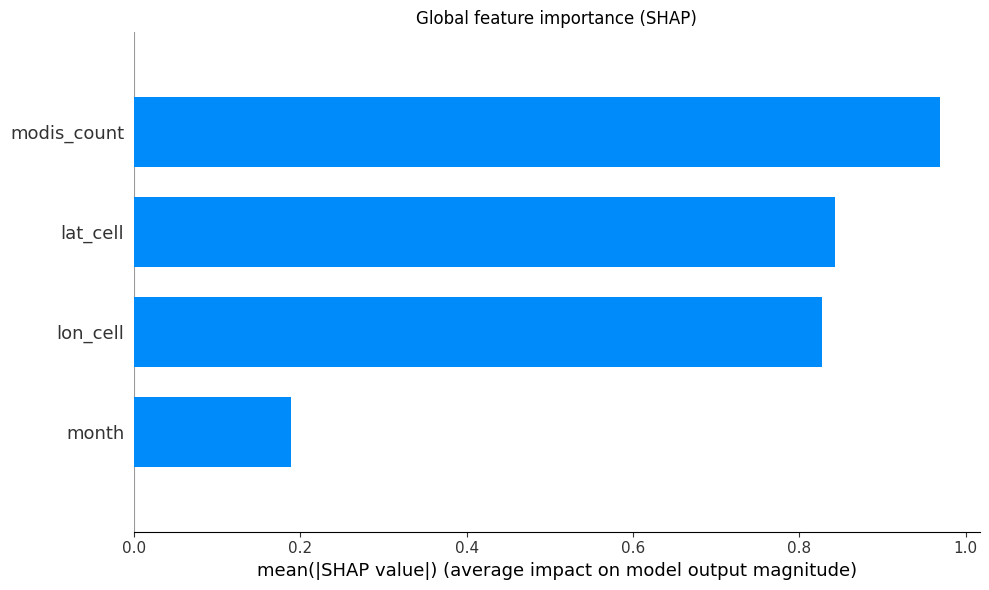

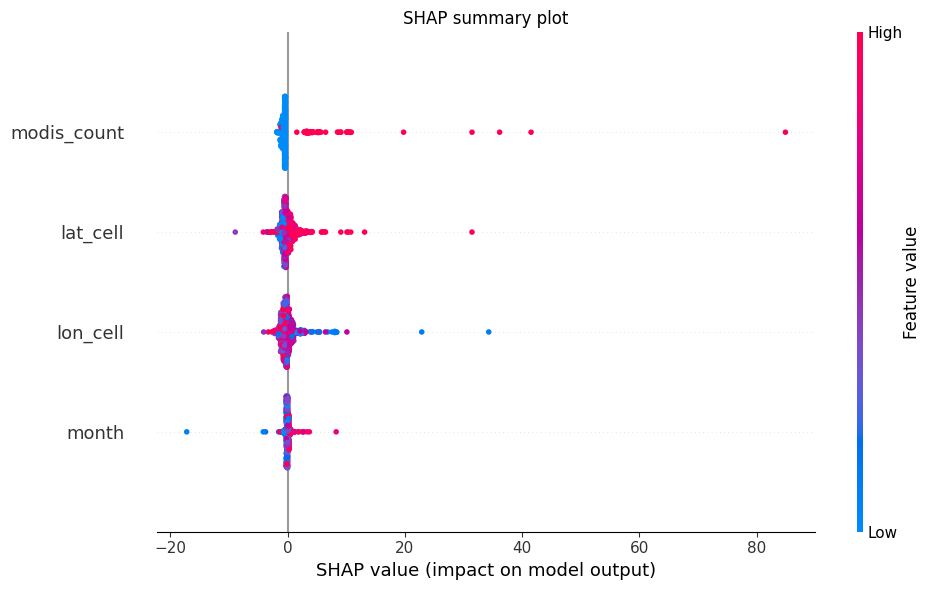

In [ ]:
ءimport shap
import matplotlib.pyplot as plt

%matplotlib inline

def explain_burnwise_model(forecaster, X_train, max_rows=1000):
    print("Initializing SHAP TreeExplainer...")

    # Use a sample so it runs fast even on a big table
    X_s = X_train.sample(min(max_rows, len(X_train)), random_state=0)

    explainer = shap.TreeExplainer(forecaster)
    shap_values = explainer.shap_values(X_s)
    print("SHAP values shape:", getattr(shap_values, "shape", len(shap_values)))

    # Bar plot: average importance of each feature
    # (plot_size replaces plt.figure(), which can leave an empty extra figure)
    shap.summary_plot(shap_values, X_s, plot_type="bar", show=False, plot_size=(10, 6))
    plt.title("Global feature importance (SHAP)")
    plt.tight_layout()
    plt.show()

    # Beeswarm: direction and size of each feature's effect
    shap.summary_plot(shap_values, X_s, show=False, plot_size=(10, 6))
    plt.title("SHAP summary plot")
    plt.tight_layout()
    plt.show()

# Call it using your notebook's actual variable names 'rf' and 'X_train'
explain_burnwise_model(rf, X_train)

1. Reconstructing training variables from local outputs...
Shape of X_train: (57720, 4)
2. TreeExplainer created successfully.
3. SHAP values calculated. Type: <class 'numpy.ndarray'>
4. Generating summary plot...


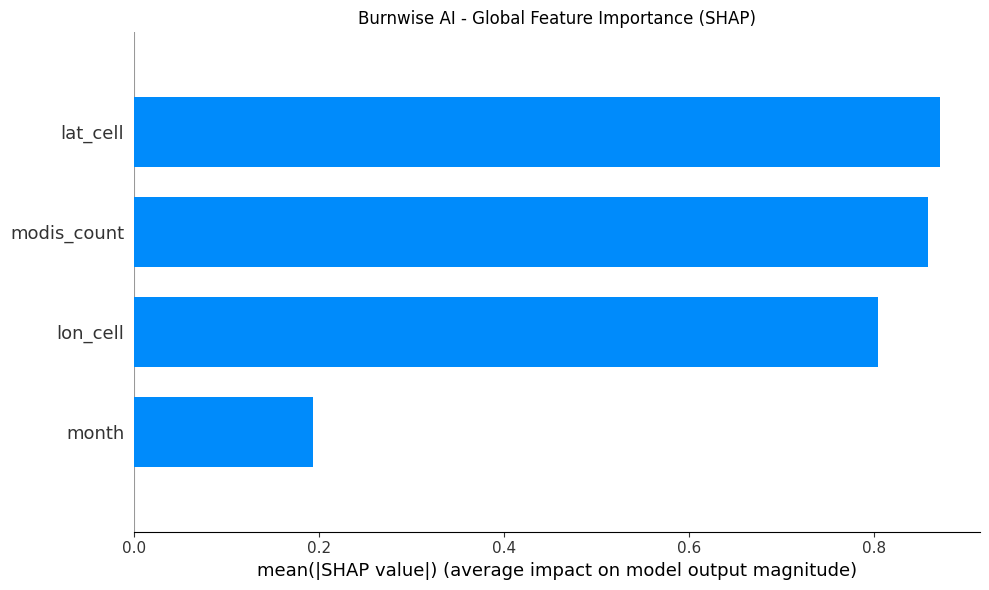

5. Plot rendered and displayed successfully!


In [ ]:
# ============================================================
# Burnwise AI: Explainable AI (SHAP) - Self-Contained Version
# ============================================================
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor

print("1. Reconstructing training variables from local outputs...")

# Re-load from your generated CSV to guarantee variables exist
grid_data = pd.read_csv("harmonized_monthly.csv")

# Rebuild the overlap train dataset (2013-2022)
train_df = grid_data[(grid_data["year"] >= 2013) & (grid_data["year"] <= 2022)]
features = ["lat_cell", "lon_cell", "month", "modis_count"]

X_train = train_df[features]
y_train = train_df["viirs_count"]

# Re-train the Random Forest Model locally in this cell
rf = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

print(f"Shape of X_train: {X_train.shape}")

# Downsample for faster SHAP calculation
max_rows = 1000
X_sample = X_train.sample(min(max_rows, len(X_train)), random_state=42)

# 2. Initialize TreeExplainer
explainer = shap.TreeExplainer(rf)
print("2. TreeExplainer created successfully.")

# 3. Calculate SHAP values
shap_values = explainer.shap_values(X_sample)
print("3. SHAP values calculated. Type:", type(shap_values))

# 4. Generate and display the Global Feature Importance Bar Plot
print("4. Generating summary plot...")
shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False, plot_size=(10, 6))
plt.title("Burnwise AI - Global Feature Importance (SHAP)")
plt.tight_layout()
plt.show()

print("5. Plot rendered and displayed successfully!")